# HW3 - PyTorch Tutorial

## PyTorch 60-Minute Blitz

This notebook follows the "Deep Learning with PyTorch: A 60 Minute Blitz" tutorial. The tutorial introduces PyTorch tensors, automatic differentiation, neural networks, and training a classifier.

In [2]:
import torch
import numpy as np

print(torch.__version__)

2.14.1+cpu


### Tensors

Tensors are similar to NumPy arrays and are used to represent the inputs, outputs, and parameters of a neural network.

In [3]:
# Create a tensor directly from data
data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)

print(x_data)

tensor([[1, 2],
        [3, 4]])


In [4]:
# Create a tensor from a NumPy array
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

print(x_np)

tensor([[1, 2],
        [3, 4]])


In [5]:
# Create tensors based on another tensor
x_ones = torch.ones_like(x_data)
print(f"Ones Tensor:\n {x_ones} \n")

x_rand = torch.rand_like(x_data, dtype=torch.float)
print(f"Random Tensor:\n {x_rand} \n")

Ones Tensor:
 tensor([[1, 1],
        [1, 1]]) 

Random Tensor:
 tensor([[0.5141, 0.9147],
        [0.8889, 0.3904]]) 



In [6]:
shape = (2, 3)

rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor:\n {rand_tensor} \n")
print(f"Ones Tensor:\n {ones_tensor} \n")
print(f"Zeros Tensor:\n {zeros_tensor}")

Random Tensor:
 tensor([[0.5409, 0.9096, 0.2184],
        [0.8080, 0.3108, 0.4841]]) 

Ones Tensor:
 tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Zeros Tensor:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


In [7]:
tensor = torch.rand(3, 4)

print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


The shape describes the dimensions of the tensor, the datatype describes the type of values stored in the tensor, and the device specifies where the tensor is stored.

In [8]:
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")

tensor[:, 1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [9]:
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


In [10]:
# Matrix multiplication
y1 = tensor @ tensor.T
y2 = tensor.matmul(tensor.T)

y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)

print(y1)
print(y2)
print(y3)

tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])


In [11]:
# Element-wise multiplication
z1 = tensor * tensor
z2 = tensor.mul(tensor)

z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)

print(z1)
print(z2)
print(z3)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [12]:
agg = tensor.sum()
agg_item = agg.item()

print(agg_item, type(agg_item))

12.0 <class 'float'>


In [13]:
print(f"{tensor} \n")
tensor.add_(5)
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor([[6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.]])


In [14]:
t = torch.ones(5)
print(f"t: {t}")

n = t.numpy()
print(f"n: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]


In [15]:
t.add_(1)

print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


In [16]:
n = np.ones(5)
t = torch.from_numpy(n)

np.add(n, 1, out=n)

print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
n: [2. 2. 2. 2. 2.]


PyTorch tensors and NumPy arrays can share the same underlying memory. As a result, modifying one in place can also modify the other.

## A Gentle Introduction to torch.autograd

PyTorch uses automatic differentiation to compute gradients during neural network training. The `torch.autograd` system keeps track of operations on tensors and uses them to compute derivatives.

In [17]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

model = resnet18(weights=ResNet18_Weights.DEFAULT)

data = torch.rand(1, 3, 64, 64)
labels = torch.rand(1, 1000)

1.1%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\kapja/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


In [18]:
prediction = model(data)
print(prediction.shape)

torch.Size([1, 1000])


In [19]:
loss = (prediction - labels).sum()
loss.backward()

In [20]:
optim = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

optim.step()

The forward pass produces the model prediction and a loss measures its error. Calling `loss.backward()` computes gradients of the loss with respect to the model parameters. The optimizer then uses these gradients to update the parameters.

In [22]:
a = torch.tensor([2., 3.], requires_grad=True)
b = torch.tensor([6., 4.], requires_grad=True)

Q = 3*a**3 - b**2

In [23]:
external_grad = torch.tensor([1., 1.])
Q.backward(gradient=external_grad)

In [24]:
print(9*a**2 == a.grad)
print(-2*b == b.grad)

tensor([True, True])
tensor([True, True])


When `requires_grad=True`, PyTorch tracks operations on a tensor in a computational graph. Calling `backward()` computes derivatives using the chain rule, and the resulting gradients are stored in the tensor's `.grad` attribute.

In [25]:
x = torch.rand(5, 5)
y = torch.rand(5, 5)
z = torch.rand((5, 5), requires_grad=True)

a = x + y
print(f"Does a require gradients? {a.requires_grad}")

b = x + z
print(f"Does b require gradients? {b.requires_grad}")

Does a require gradients? False
Does b require gradients? True


In [26]:
print(z.requires_grad)

with torch.no_grad():
    print((x + z).requires_grad)

True
False


In [27]:
z_det = z.detach()

print(z_det.requires_grad)

False


Gradient tracking is useful during training but is unnecessary when model parameters are not being updated. `torch.no_grad()` temporarily disables gradient tracking, while `.detach()` creates a tensor detached from the computational graph.

## Neural Networks

Neural networks can be constructed in PyTorch using the `torch.nn` package. A network is defined as a class that inherits from `nn.Module`, with layers defined in the constructor and the forward computation defined in `forward()`.

In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [29]:
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, input):
        c1 = F.relu(self.conv1(input))
        s2 = F.max_pool2d(c1, (2, 2))
        c3 = F.relu(self.conv2(s2))
        s4 = F.max_pool2d(c3, 2)
        s4 = torch.flatten(s4, 1)
        f5 = F.relu(self.fc1(s4))
        f6 = F.relu(self.fc2(f5))
        output = self.fc3(f6)
        return output


net = Net()
print(net)

Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [30]:
params = list(net.parameters())

print(len(params))
print(params[0].size())

10
torch.Size([6, 1, 5, 5])


In [31]:
input = torch.randn(1, 1, 32, 32)
out = net(input)

print(out)

tensor([[-0.0248,  0.0885, -0.0858, -0.0193,  0.0083, -0.0373,  0.0932,  0.0524,
          0.0321, -0.0105]], grad_fn=<AddmmBackward0>)


In [32]:
net.zero_grad()
out.backward(torch.randn(1, 10))

The network's learnable parameters consist of weights and biases that are automatically registered by `nn.Module`. A forward pass computes the network output, while a backward pass computes gradients for these parameters.

In [33]:
output = net(input)

target = torch.randn(10)
target = target.view(1, -1)

criterion = nn.MSELoss()

loss = criterion(output, target)
print(loss)

tensor(0.8794, grad_fn=<MseLossBackward0>)


In [34]:
print(loss.grad_fn)
print(loss.grad_fn.next_functions[0][0])
print(loss.grad_fn.next_functions[0][0].next_functions[0][0])

The loss function provides a scalar measure of prediction error. Because the loss remains connected to the computational graph, autograd can trace backward from the loss through the network to calculate gradients for the learnable parameters.

In [35]:
net.zero_grad()

print("conv1.bias.grad before backward")
print(net.conv1.bias.grad)

loss.backward()

print("conv1.bias.grad after backward")
print(net.conv1.bias.grad)

conv1.bias.grad before backward
None
conv1.bias.grad after backward
tensor([0.0030, 0.0012, 0.0002, 0.0081, 0.0039, 0.0015])


Backpropagation computes the gradient of the loss with respect to each learnable parameter in the network. PyTorch performs this automatically when `loss.backward()` is called, and the resulting gradients are stored in each parameter's `.grad` attribute.

In [36]:
import torch.optim as optim

optimizer = optim.SGD(net.parameters(), lr=0.01)

optimizer.zero_grad()
output = net(input)
loss = criterion(output, target)
loss.backward()
optimizer.step()

A training step consists of clearing old gradients, performing a forward pass, computing the loss, performing backpropagation, and updating the parameters with an optimizer. Here, stochastic gradient descent (SGD) is used to update the network parameters.

In [37]:
learning_rate = 0.01

for f in net.parameters():
    f.data.sub_(f.grad.data * learning_rate)

In [38]:
import torch.optim as optim

optimizer = optim.SGD(net.parameters(), lr=0.01)

optimizer.zero_grad()
output = net(input)
loss = criterion(output, target)
loss.backward()
optimizer.step()

## Training a Classifier

In this section, a convolutional neural network is trained to classify images from the CIFAR-10 dataset. The process consists of loading and normalizing the data, defining the network, defining a loss function and optimizer, training the network, and evaluating its performance.

In [39]:
import torch
import torchvision
import torchvision.transforms as transforms

In [40]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5),
                          (0.5, 0.5, 0.5))]
)

In [41]:
batch_size = 4

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

100.0%


In [42]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

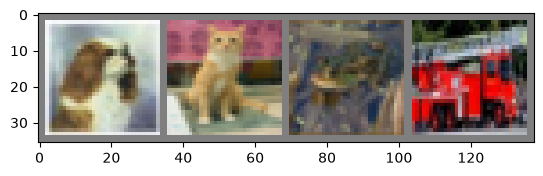

dog   cat   frog  truck


In [43]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [44]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [45]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [46]:
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

        if i % 2000 == 1999:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

[1,  2000] loss: 2.208
[1,  4000] loss: 1.937
[1,  6000] loss: 1.732
[1,  8000] loss: 1.610
[1, 10000] loss: 1.537
[1, 12000] loss: 1.479
[2,  2000] loss: 1.413
[2,  4000] loss: 1.390
[2,  6000] loss: 1.354
[2,  8000] loss: 1.339
[2, 10000] loss: 1.315
[2, 12000] loss: 1.296
Finished Training


In [47]:
PATH = './cifar_net.pth'
torch.save(net.state_dict(), PATH)

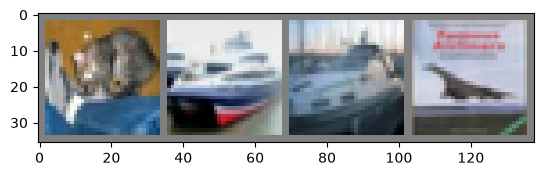

GroundTruth:  cat   ship  ship  plane


In [48]:
dataiter = iter(testloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

print('GroundTruth: ', ' '.join(
    f'{classes[labels[j]]:5s}' for j in range(4)
))

In [49]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [50]:
outputs = net(images)

_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(
    f'{classes[predicted[j]]:5s}' for j in range(4)
))

Predicted:  cat   plane ship  plane


In [51]:
correct = 0
total = 0

with torch.no_grad():
    for data in testloader:
        images, labels = data

        outputs = net(images)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 53 %


In [52]:
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)

        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 74.4 %
Accuracy for class: car   is 60.0 %
Accuracy for class: bird  is 26.9 %
Accuracy for class: cat   is 47.4 %
Accuracy for class: deer  is 41.0 %
Accuracy for class: dog   is 28.2 %
Accuracy for class: frog  is 73.3 %
Accuracy for class: horse is 73.5 %
Accuracy for class: ship  is 51.8 %
Accuracy for class: truck is 62.9 %


### Training on GPU

In [53]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print(device)

cpu


In [54]:
net.to(device)

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [55]:
inputs, labels = data[0].to(device), data[1].to(device)

PyTorch can train neural networks on a GPU by moving both the model and the data to a CUDA device. On this system, CUDA is not available, so the network is trained on the CPU.